## Objective

Build Predictive model or classification model for booking_status.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

### Load the dataset

In [2]:
data = pd.read_csv("Hotel Reservations.csv")
data.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,0,1,224,2017,10,2,2,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,0,1,5,2018,11,6,1,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,0,1,1,2018,2,28,1,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,0,1,211,2018,5,20,1,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,0,1,48,2018,4,11,1,0,0,0,94.50,0,Canceled


In [3]:
data.shape

(36275, 18)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 18 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   required_car_parking_space            36275 non-null  int64  
 6   room_type_reserved                    36275 non-null  int64  
 7   lead_time                             36275 non-null  int64  
 8   arrival_year                          36275 non-null  int64  
 9   arrival_month                         36275 non-null  int64  
 10  arrival_date                          36275 non-null  int64  
 11  market_segment_

In [5]:
data['Booking_ID'].nunique() # high cardinality - a column will have so many unique values , we try to avoid using that column for making predictions. Because that columns doesn't add something new in order to get analyzed by the model




36275

## Data Preprocessing

In [6]:
data["Booking_ID"].nunique()

36275

#### Drop Booking id as it has nothing to do with prediction

In [7]:
data = data.drop(columns=['Booking_ID'])

## Encoding

In [8]:
data

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,1,2,0,1,224,2017,10,2,2,0,0,0,65.00,0,Not_Canceled
1,2,0,2,3,0,1,5,2018,11,6,1,0,0,0,106.68,1,Not_Canceled
2,1,0,2,1,0,1,1,2018,2,28,1,0,0,0,60.00,0,Canceled
3,2,0,0,2,0,1,211,2018,5,20,1,0,0,0,100.00,0,Canceled
4,2,0,1,1,0,1,48,2018,4,11,1,0,0,0,94.50,0,Canceled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36270,3,0,2,6,0,4,85,2018,8,3,1,0,0,0,167.80,1,Not_Canceled
36271,2,0,1,3,0,1,228,2018,10,17,1,0,0,0,90.95,2,Canceled
36272,2,0,2,6,0,1,148,2018,7,1,1,0,0,0,98.39,2,Not_Canceled
36273,2,0,0,3,0,1,63,2018,4,21,1,0,0,0,94.50,0,Canceled


In [9]:
data.select_dtypes(include="object")

,booking_status
0,Not_Canceled
1,Not_Canceled
2,Canceled
3,Canceled
4,Canceled
...,...
36270,Not_Canceled
36271,Canceled
36272,Not_Canceled
36273,Canceled


In [10]:
data['booking_status'].value_counts()

booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64

In [11]:
data['booking_status'].value_counts()/data.shape[0]*100

booking_status
Not_Canceled    67.236389
Canceled        32.763611
Name: count, dtype: float64

In [ ]:
# one hot encoding

Booking_status.    Not_canceled.     Canceled
Not_canceled         1                 0
canceled             0                  1
Not_canceled         1                  0
Not_canceled         1                  0
canceled             0                  1
Not_canceled

In [12]:
data = pd.get_dummies(data, columns=['booking_status'], dtype=int)

In [13]:
data.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status_Canceled,booking_status_Not_Canceled
0,2,0,1,2,0,1,224,2017,10,2,2,0,0,0,65.00,0,0,1
1,2,0,2,3,0,1,5,2018,11,6,1,0,0,0,106.68,1,0,1
2,1,0,2,1,0,1,1,2018,2,28,1,0,0,0,60.00,0,1,0
3,2,0,0,2,0,1,211,2018,5,20,1,0,0,0,100.00,0,1,0
4,2,0,1,1,0,1,48,2018,4,11,1,0,0,0,94.50,0,1,0


In [14]:
data.drop(['booking_status_Not_Canceled'],axis=1,inplace=True)

In [15]:
data.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status_Canceled
0,2,0,1,2,0,1,224,2017,10,2,2,0,0,0,65.00,0,0
1,2,0,2,3,0,1,5,2018,11,6,1,0,0,0,106.68,1,0
2,1,0,2,1,0,1,1,2018,2,28,1,0,0,0,60.00,0,1
3,2,0,0,2,0,1,211,2018,5,20,1,0,0,0,100.00,0,1
4,2,0,1,1,0,1,48,2018,4,11,1,0,0,0,94.50,0,1


    Not_Canceled: 0
    Cancelled:1

In [16]:
data['booking_status_Canceled'].value_counts()

booking_status_Canceled
0    24390
1    11885
Name: count, dtype: int64

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 17 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          36275 non-null  int64  
 1   no_of_children                        36275 non-null  int64  
 2   no_of_weekend_nights                  36275 non-null  int64  
 3   no_of_week_nights                     36275 non-null  int64  
 4   required_car_parking_space            36275 non-null  int64  
 5   room_type_reserved                    36275 non-null  int64  
 6   lead_time                             36275 non-null  int64  
 7   arrival_year                          36275 non-null  int64  
 8   arrival_month                         36275 non-null  int64  
 9   arrival_date                          36275 non-null  int64  
 10  market_segment_type                   36275 non-null  int64  
 11  repeated_guest 

# KNN

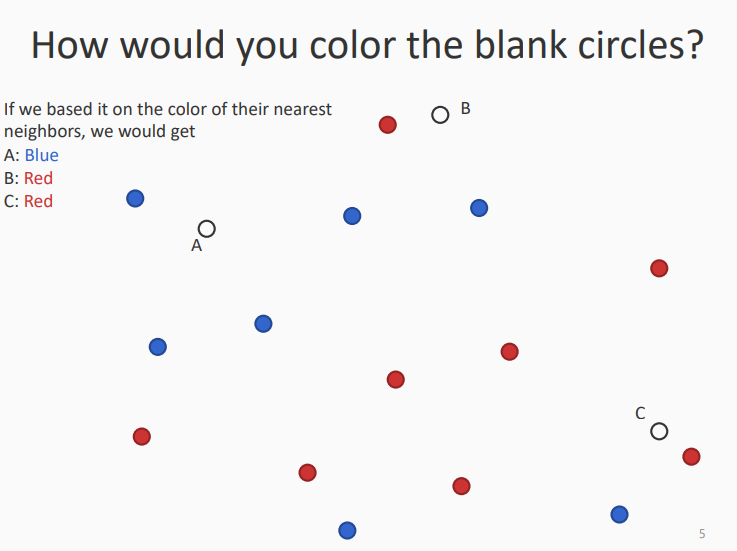

**In simple terms:**

    Step-1: Select the number K of the neighbors
    Step-2: Calculate the Euclidean distance between the new point and all the other points.
    
  $ \text{Euclidean Distance} = \sqrt{{(x_2 - x_1)^2 + (y_2 - y_1)^2 + (z_2 - z_1)^2 + \ldots}} $

    Step-3: Take the K nearest neighbors as per the calculated Euclidean distance.
    Step-4: Among these k neighbors, count the number of the data points in each category.
    Step-5: Assign the new data points to that category for which the number of the neighbor is maximum.


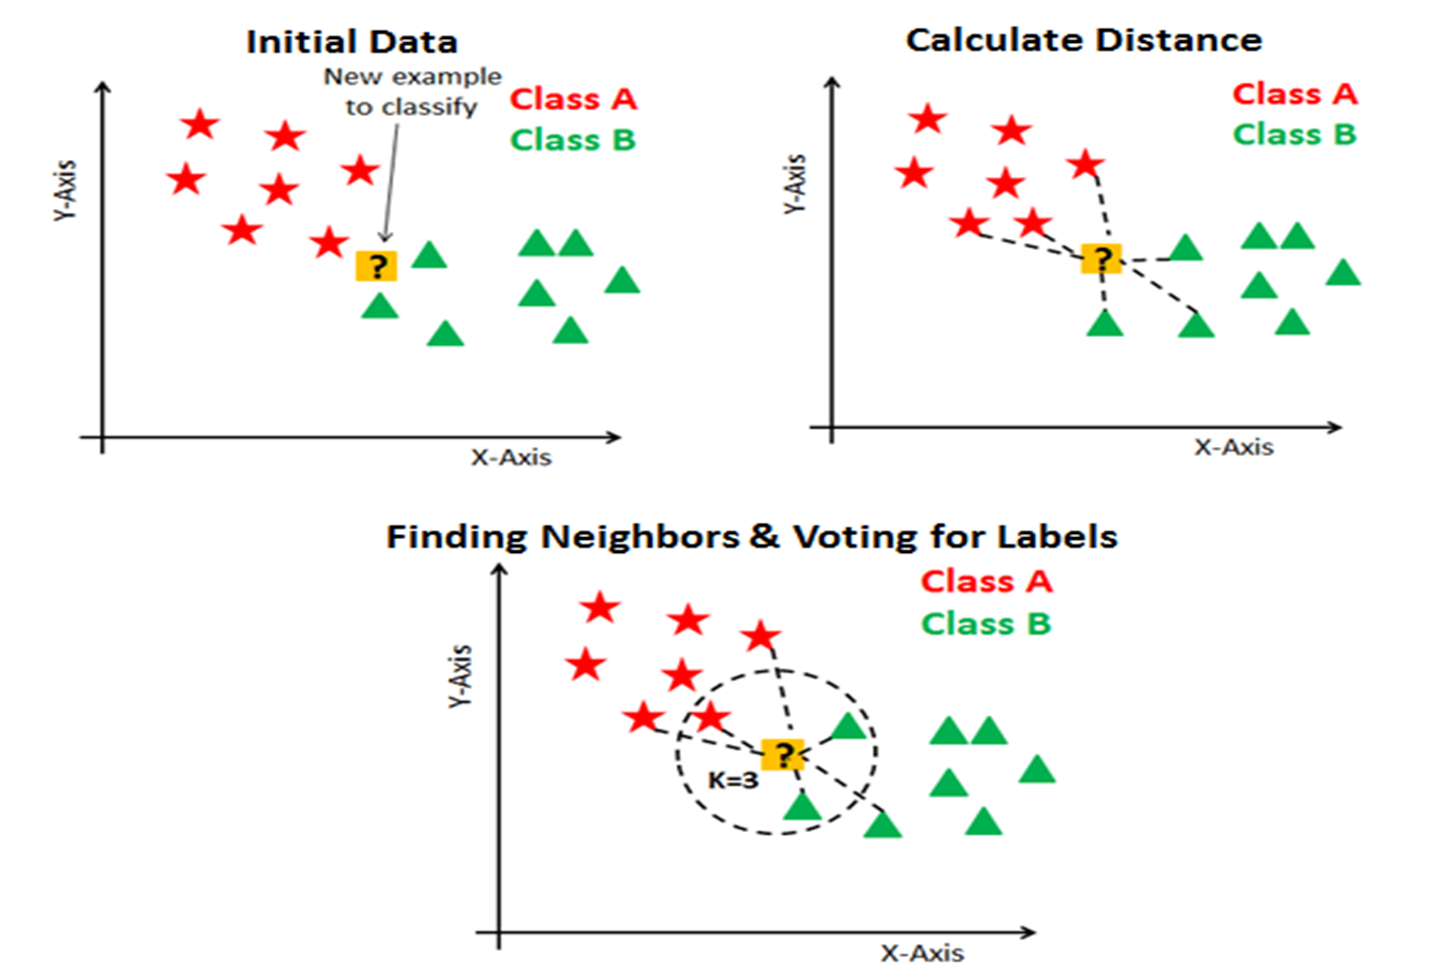

# Define Features and Target column

    1. Define x and y
    2. split into train and test
    3. model train
    4. model test
    5. evaluate

In [ ]:
data.head(2)

In [18]:
X = data.drop('booking_status_Canceled', axis=1)   #features
y = data['booking_status_Canceled']                #targets

In [19]:
data.booking_status_Canceled

0        0
1        0
2        1
3        1
4        1
        ..
36270    0
36271    1
36272    0
36273    1
36274    0
Name: booking_status_Canceled, Length: 36275, dtype: int64

In [20]:
y

0        0
1        0
2        1
3        1
4        1
        ..
36270    0
36271    1
36272    0
36273    1
36274    0
Name: booking_status_Canceled, Length: 36275, dtype: int64

# X

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,  y,  test_size=0.30)
#70% features for training x_train  + 70% labels y_train
#30% features for testing   x_test   + 30%  labels y_test

In [23]:
data.describe()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status_Canceled
count,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000
mean,1.844962,0.105279,0.810724,2.204300,0.030986,1.708890,85.232557,2017.820427,7.423653,15.596995,1.454886,0.025637,0.023349,0.153411,103.423539,0.619655,0.327636
std,0.518715,0.402648,0.870644,1.410905,0.173281,1.399851,85.930817,0.383836,3.069894,8.740447,0.713586,0.158053,0.368331,1.754171,35.089424,0.786236,0.469358
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2017.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,1.000000,17.000000,2018.000000,5.000000,8.000000,1.000000,0.000000,0.000000,0.000000,80.300000,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,1.000000,57.000000,2018.000000,8.000000,16.000000,1.000000,0.000000,0.000000,0.000000,99.450000,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,1.000000,126.000000,2018.000000,10.000000,23.000000,2.000000,0.000000,0.000000,0.000000,120.000000,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,7.000000,443.000000,2018.000000,12.000000,31.000000,5.000000,1.000000,13.000000,58.000000,540.000000,5.000000,1.000000


In [24]:

IQR = data.lead_time.quantile(0.75) - data.lead_time.quantile(0.25)
Lower_fence = data.lead_time.quantile(0.25) - (IQR * 3)
Upper_fence = data.lead_time.quantile(0.75) + (IQR * 3)
print('Lead Time outliers are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))


Lead Time outliers are values < -310.0 or > 453.0


In [25]:

IQR = data.avg_price_per_room.quantile(0.75) - data.avg_price_per_room.quantile(0.25)
Lower_fence = data.avg_price_per_room.quantile(0.25) - (IQR * 3)
Upper_fence = data.avg_price_per_room.quantile(0.75) + (IQR * 3)
print('avg_price_per_room are values < {lowerboundary} or > {upperboundary}'.format(lowerboundary=Lower_fence, upperboundary=Upper_fence))


avg_price_per_room are values < -38.80000000000001 or > 239.10000000000002


In [26]:
data.shape

(36275, 17)

In [27]:
def max_value(df3, variable, top):
    return np.where(df3[variable]>top, top, df3[variable])

data['lead_time'] = max_value(data, 'lead_time', 453)
data['avg_price_per_room'] = max_value(data, 'avg_price_per_room', 239.1)

In [28]:
data['lead_time'].max()

443

In [29]:
data['avg_price_per_room'].max()

239.1

In [30]:
data.shape

(36275, 17)

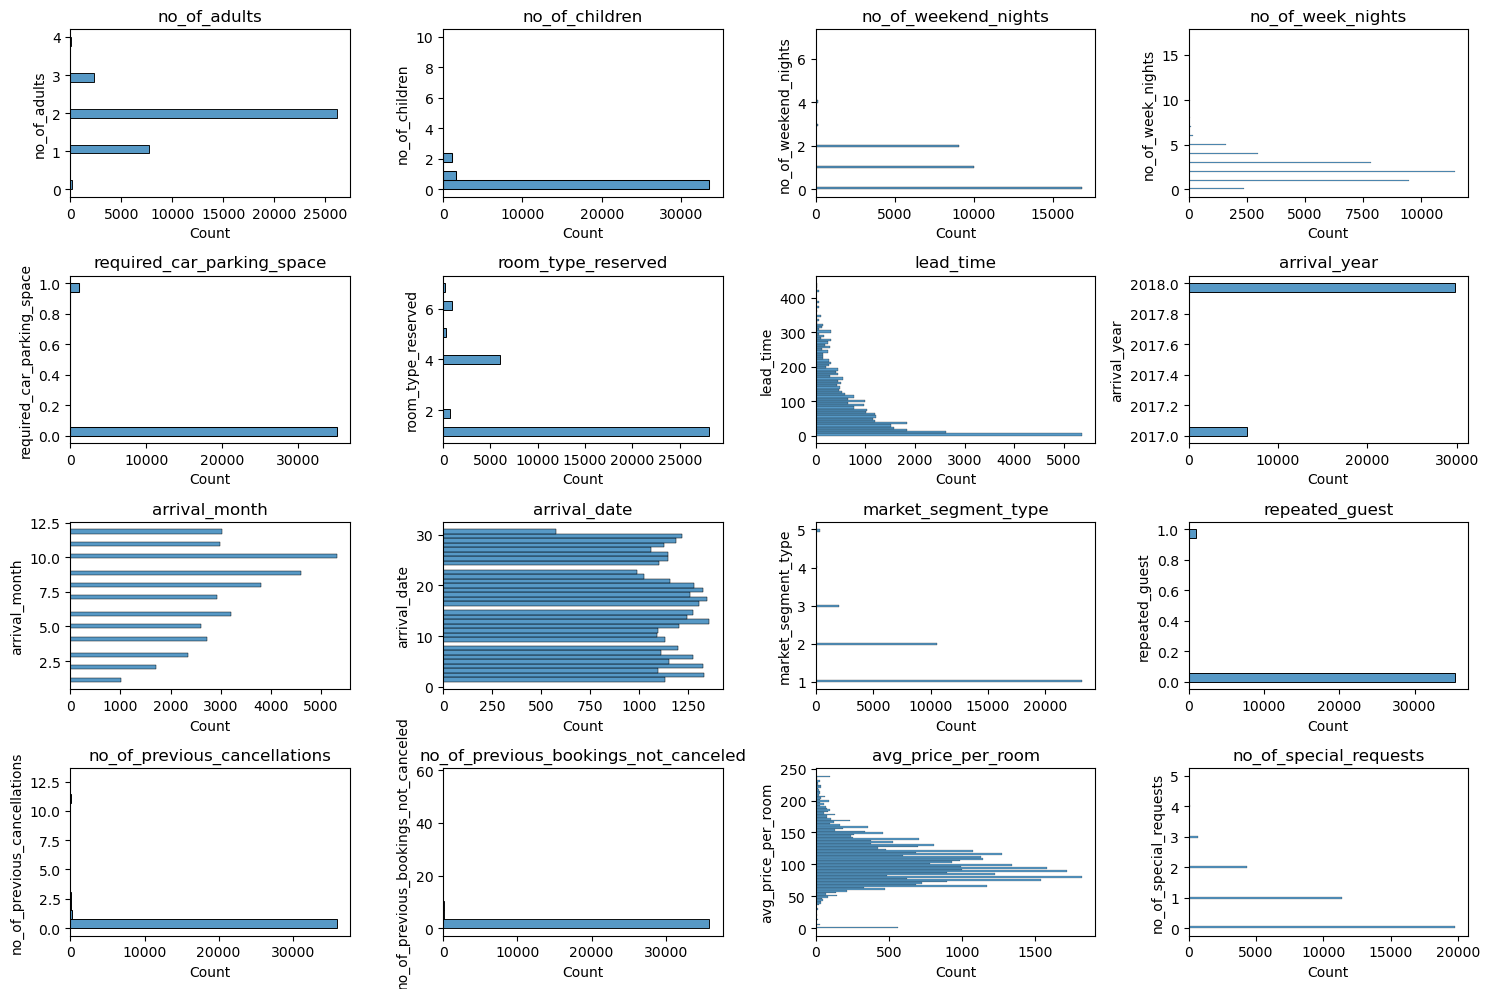

In [33]:
# Boxplots to visualize outliers in the dataset
plt.figure(figsize=(15, 10))

# Creating a boxplot for each feature in the DataFrame
for i, column in enumerate(data.drop(columns=['booking_status_Canceled'])):
    plt.subplot(4, 4, i + 1)
    sns.histplot(y=data[column])
    plt.title(column)
    plt.tight_layout()

plt.show()

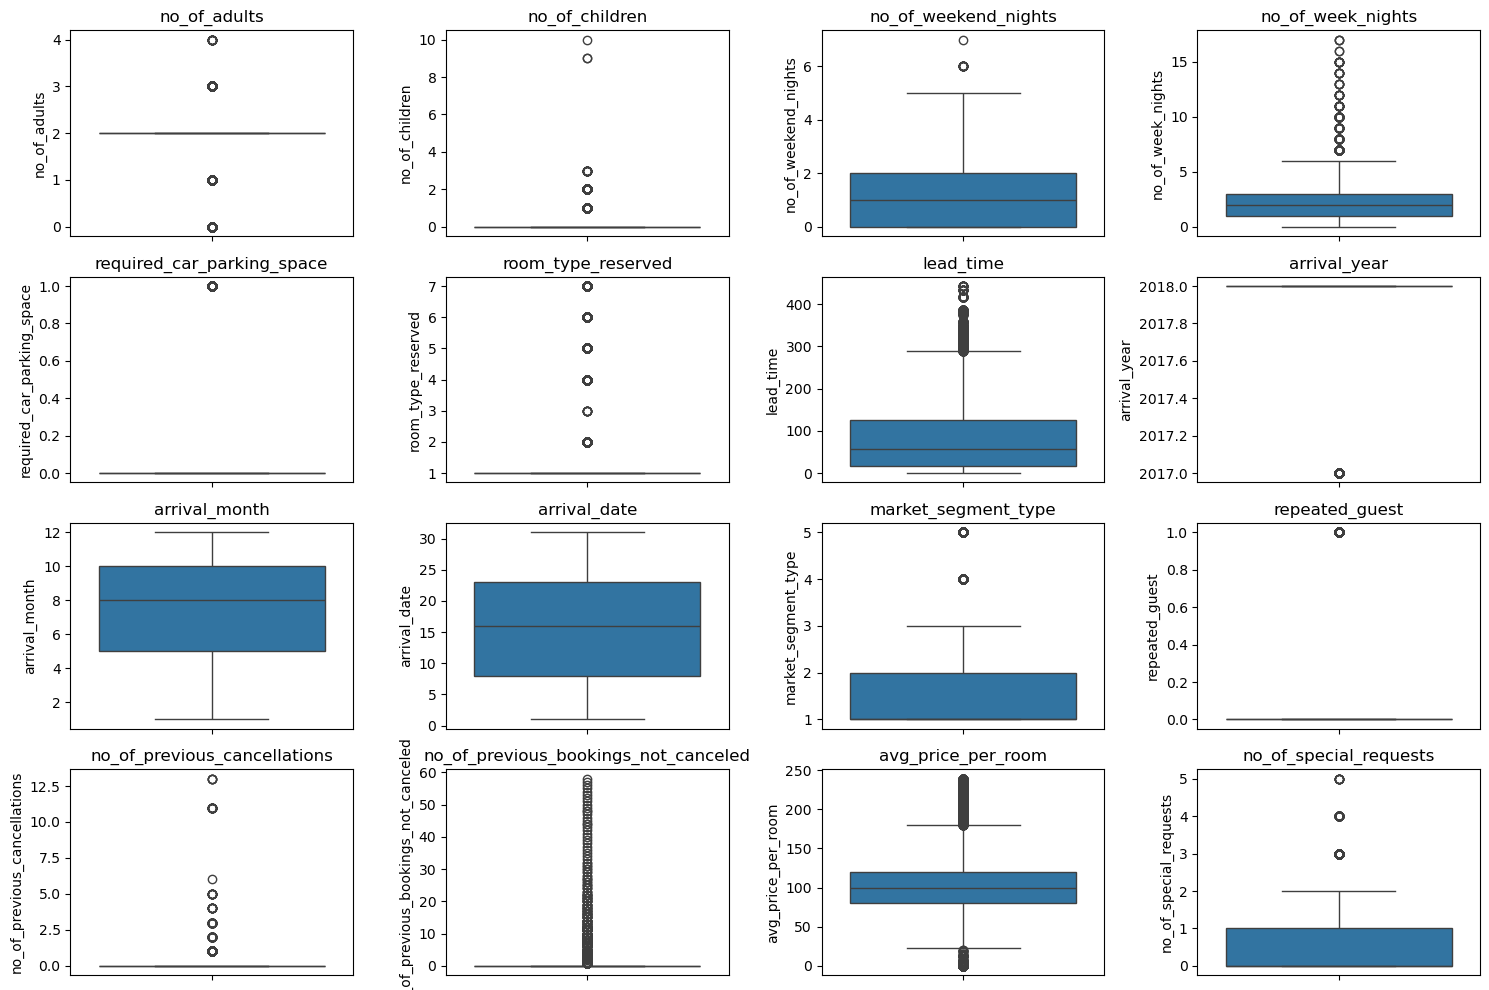

In [32]:
# Boxplots to visualize outliers in the dataset
plt.figure(figsize=(15, 10))

# Creating a boxplot for each feature in the DataFrame
for i, column in enumerate(data.drop(columns=['booking_status_Canceled'])):
    plt.subplot(4, 4, i + 1)
    sns.boxplot(y=data[column])
    plt.title(column)
    plt.tight_layout()

plt.show()

In [49]:
data['booking_status_Canceled'].value_counts()

booking_status_Canceled
0    24390
1    11885
Name: count, dtype: int64

## Feature Scaling

In [34]:
from sklearn.preprocessing import MinMaxScaler # if the distribution of columns look normal - standardscaling

In [35]:
# standardize the features

standardization = MinMaxScaler()

In [36]:
X_train= standardization.fit_transform(X_train)

In [37]:
X_test=standardization.transform(X_test)

In [38]:
X_train

array([[0.5       , 0.1       , 0.14285714, ..., 0.        , 0.17237037,
        0.2       ],
       [0.5       , 0.        , 0.14285714, ..., 0.        , 0.16481481,
        0.        ],
       [0.25      , 0.        , 0.        , ..., 0.        , 0.2037037 ,
        0.        ],
       ...,
       [0.5       , 0.        , 0.        , ..., 0.        , 0.18796296,
        0.        ],
       [0.5       , 0.        , 0.        , ..., 0.        , 0.18935185,
        0.2       ],
       [0.5       , 0.2       , 0.        , ..., 0.        , 0.415     ,
        0.4       ]])

In [39]:
X_test

array([[0.5       , 0.        , 0.        , ..., 0.        , 0.14387037,
        0.2       ],
       [0.5       , 0.2       , 0.        , ..., 0.        , 0.16064815,
        0.        ],
       [0.5       , 0.        , 0.        , ..., 0.        , 0.17333333,
        0.2       ],
       ...,
       [0.5       , 0.        , 0.        , ..., 0.        , 0.21296296,
        0.2       ],
       [0.5       , 0.        , 0.        , ..., 0.        , 0.15657407,
        0.4       ],
       [0.75      , 0.        , 0.28571429, ..., 0.        , 0.27166667,
        0.2       ]])

In [ ]:
# To know the other parameters like random_state and shuffle, run given code
#X_train, X_test, y_train, y_test = train_test_split?

## KNN Implementation
 
Remember that we are trying to come up with a model to predict whether someone will TARGET CLASS or not. We'll start with k=1.

In [40]:
from sklearn.neighbors import KNeighborsClassifier

In [75]:
knn = KNeighborsClassifier(n_neighbors=3,weights="distance")

In [76]:
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=3, weights='distance')

In [77]:
pred = knn.predict(X_test)

In [78]:
pred

array([0, 1, 0, ..., 1, 0, 0])

### Confusion Matrix:

A confusion matrix is a table that describes the performance of a classification model. It shows the counts of True Positives (TP), True Negatives (TN), False Positives (FP), and False Negatives (FN). In a binary classification scenario (two classes: Positive and Negative), the confusion matrix looks like this:


\begin{array}{ccc}
& \text{Predicted Negative} & \text{Predicted Positive} \\
\text{Actual Negative} & TN & FP \\
\text{Actual Positive} & FN & TP \\
\end{array}

Here's a breakdown of each term:

- **True Positives (TP):** Instances correctly predicted as Positive.
- **True Negatives (TN):** Instances correctly predicted as Negative.
- **False Positives (FP):** Instances incorrectly predicted as Positive.
- **False Negatives (FN):** Instances incorrectly predicted as Negative.

### Classification Report:

A classification report provides key metrics for evaluating the performance of a classification model. It includes Precision, Recall, F1 Score, Support, and Accuracy. For a binary classification scenario:


\begin{array}{ccccccc}
& \text{Precision} & \text{Recall} & \text{F1 Score} & \text{Support} & \text{Accuracy} \\
\text{Positive Class} & \frac{TP}{TP + FP} & \frac{TP}{TP + FN} & \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} & TP + FN & \frac{TP + TN}{TP + TN + FP + FN} \\
\text{Negative Class} & \frac{TN}{TN + FN} & \frac{TN}{TN + FP} & & TN + FP & \\
\end{array}


Here's a breakdown of each metric:

- **Precision:** Out of the predicted Positive instances, how many were truly Positive.
- **Recall:** Out of all the actual Positive instances, how many were correctly predicted as Positive.
- **F1 Score:** The harmonic mean of Precision and Recall, providing a balance between the two.
- **Support:** The number of actual instances for each class.
- **Accuracy:** Overall correctness of the model.

In a multiclass scenario, these metrics are usually calculated for each class, and the classification report includes a row for each class.

These metrics help in assessing the model's performance and understanding how well it distinguishes between different classes.

## Predictions and Evaluations

Let's evaluate our KNN model!

In [79]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score

In [80]:
print(confusion_matrix(y_test,pred))

[[6633  699]
 [ 800 2751]]


In [81]:
accuracy_score(y_test,pred)

0.8622622438665809

In [82]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.89      0.90      0.90      7332
           1       0.80      0.77      0.79      3551

    accuracy                           0.86     10883
   macro avg       0.84      0.84      0.84     10883
weighted avg       0.86      0.86      0.86     10883



In [83]:
#Training Accuracy
print(knn.score(X_train, y_train))

0.9940138626339005


In [72]:
#Testing Accuracy
print(knn.score(X_test, y_test))

0.8749425709822659


If model is overfit (training accuracy = 100 % while less testing accuracy):
    
    1. Change the k value
    2. add randomness or shuffle parameter in train_test_split
    3. cross validation
    

In [73]:
import math
math.sqrt(data.shape[0])

190.4599695474091

## Choosing a K Value

Let's go ahead and use the elbow method to pick a good K Value:

Minimum error: 0.1238629054488652 at K = 33


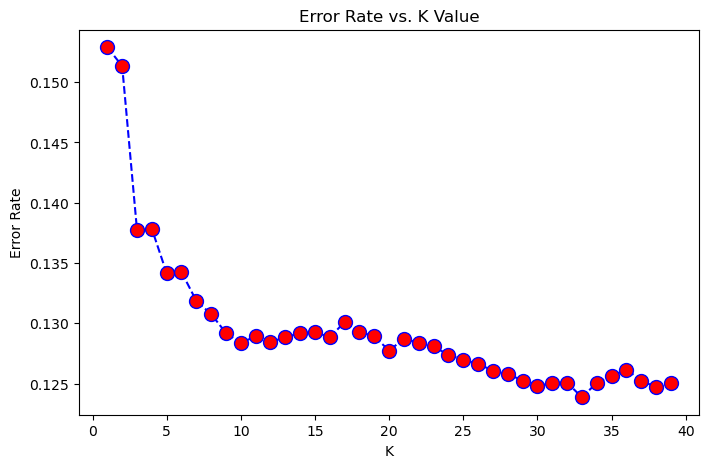

In [74]:
error_rate = []
for i in range(1,40):
    knn = KNeighborsClassifier(n_neighbors=i,weights="distance")
    knn.fit(X_train,y_train)
    pred_i = knn.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))
    
plt.figure(figsize=(8,5))
plt.plot(range(1,40),error_rate,color='blue', linestyle='dashed', marker='o',markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
print("Minimum error:",min(error_rate),"at K =",error_rate.index(min(error_rate))+1)

Maximum accuracy: 0.8488468253238997 at K = 3


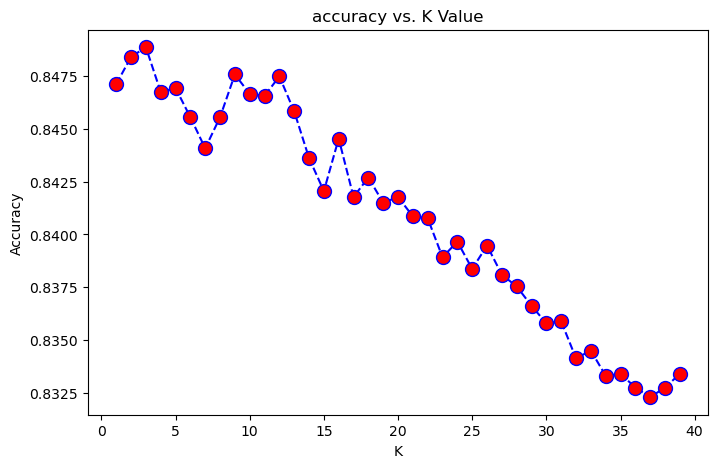

In [84]:
acc = []
# Will take some time
from sklearn import metrics
for i in range(1,40):
    neigh = KNeighborsClassifier(n_neighbors = i).fit(X_train,y_train)
    yhat = neigh.predict(X_test)
    acc.append(metrics.accuracy_score(y_test, yhat))

plt.figure(figsize=(8,5))
plt.plot(range(1,40),acc,color = 'blue',linestyle='dashed',
         marker='o',markerfacecolor='red', markersize=10)
plt.title('accuracy vs. K Value')
plt.xlabel('K')
plt.ylabel('Accuracy')
print("Maximum accuracy:",max(acc),"at K =",acc.index(max(acc))+1)

In [87]:
knn = KNeighborsClassifier(n_neighbors=4,weights="distance")

knn.fit(X_train,y_train)
pred = knn.predict(X_test)

print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.89      0.90      0.90      7332
           1       0.80      0.78      0.79      3551

    accuracy                           0.86     10883
   macro avg       0.84      0.84      0.84     10883
weighted avg       0.86      0.86      0.86     10883



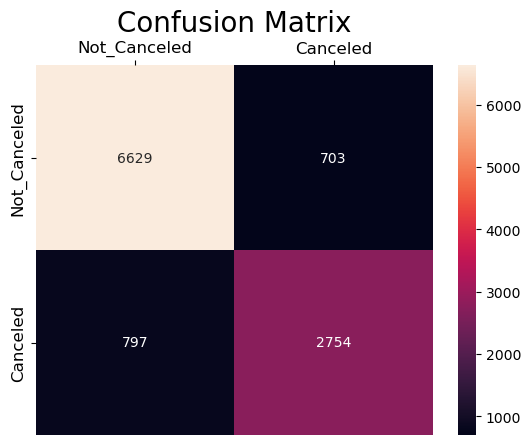

In [88]:
ax= plt.subplot()
sns.heatmap(confusion_matrix(y_test,pred), annot=True, ax = ax, fmt = 'g'); 
ax.set_title('Confusion Matrix', fontsize=20)

ax.xaxis.set_ticklabels(['Not_Canceled','Canceled'], fontsize = 12)
ax.xaxis.tick_top()

ax.yaxis.set_ticklabels(['Not_Canceled','Canceled'], fontsize = 12)
plt.show()

## Basic Deployment

In [89]:
data.columns

Index(['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'required_car_parking_space', 'room_type_reserved',
       'lead_time', 'arrival_year', 'arrival_month', 'arrival_date',
       'market_segment_type', 'repeated_guest', 'no_of_previous_cancellations',
       'no_of_previous_bookings_not_canceled', 'avg_price_per_room',
       'no_of_special_requests', 'booking_status_Canceled'],
      dtype='object')

##### data.head()

In [91]:
def predict_booking_cancellation(model, scaler):
    # Input data from user
    no_of_adults = int(input("Enter number of adults: "))
    no_of_children = int(input("Enter number of children: "))
    no_of_weekend_nights = int(input("Enter number of weekend nights: "))
    no_of_week_nights = int(input("Enter number of week nights: "))
    required_car_parking_space = int(input("Required car parking space (0/1): "))
    room_type_reserved = input("Enter room type reserved (Room Type 1/Room Type 2/Room Type 3/Room Type 4/Room Type 5/Room Type 6/Room Type 7): ")
    lead_time = int(input("Enter lead time: "))
    arrival_year = int(input("Enter arrival year: "))
    arrival_month = int(input("Enter arrival month: "))
    arrival_date = int(input("Enter arrival date: "))
    market_segment_type = input("Enter market segment type: ")
    repeated_guest = int(input("Repeated guest (0/1): "))
    no_of_previous_cancellations = int(input("Enter number of previous cancellations: "))
    no_of_previous_bookings_not_canceled = int(input("Enter number of previous bookings not canceled: "))
    avg_price_per_room = float(input("Enter average price per room: "))
    no_of_special_requests = int(input("Enter number of special requests: "))

    # Create a dataframe for the input data
    input_data = pd.DataFrame([[
        no_of_adults, no_of_children, no_of_weekend_nights, no_of_week_nights,
        required_car_parking_space, room_type_reserved,
        lead_time, arrival_year, arrival_month, arrival_date, market_segment_type,
        repeated_guest, no_of_previous_cancellations,
        no_of_previous_bookings_not_canceled, avg_price_per_room,
        no_of_special_requests,0
    ]], columns=[
        'no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights',
        'required_car_parking_space', 'room_type_reserved',
        'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'market_segment_type',
        'repeated_guest', 'no_of_previous_cancellations',
        'no_of_previous_bookings_not_canceled', 'avg_price_per_room',
        'no_of_special_requests','booking_status'
    ]) 

    input_data.drop(['booking_status'],axis=1,inplace=True)
    # Apply feature scaling
    input_data_scaled = scaler.transform(input_data)

    # Predict the booking status
    prediction = model.predict(input_data_scaled)
    
    print("\n\n Prediction:")
    # Output the result
    if prediction[0] == 0:
        print("The booking is not likely to be canceled.")
    else:
        print("The booking is likely to be canceled.")


In [92]:
predict_booking_cancellation(knn, standardization)

Enter number of adults:  2
Enter number of children:  0
Enter number of weekend nights:  1
Enter number of week nights:  1
Required car parking space (0/1):  1
Enter room type reserved (Room Type 1/Room Type 2/Room Type 3/Room Type 4/Room Type 5/Room Type 6/Room Type 7):  1
Enter lead time:  150
Enter arrival year:  2018
Enter arrival month:  12
Enter arrival date:  25
Enter market segment type:  1
Repeated guest (0/1):  1
Enter number of previous cancellations:  0
Enter number of previous bookings not canceled:  2
Enter average price per room:  250
Enter number of special requests:  0




 Prediction:
The booking is not likely to be canceled.


In [93]:
import pickle

with open('hotel-prediction-model.pkl',"wb") as file:
    pickle.dump(knn,file)